In [ ]:
#Abigail Birnbaum (abigail.birnbaum@pnnl.gov)
#Last updated 2026-10-12
#Create CSVs converting 12km weather forcings grid cells to basin scale (NCAR delineations)

# Import Statements

In [1]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from calendar import monthrange
import time

import xarray as xr
import rioxarray as rio
import rasterio
from rasterio.enums import Resampling
import shapely

# Define Methods

In [2]:
def create_grid(grid_dist,grid_bounds,crs_ref):
    """Function to create geodataframe of polygon boxes representing a uniform spatial grid.
    Inputs:
    grid_dist: spatial resolution of grid cell
    grid_cells: geodataframe containing grid as point values, assume lat/lon represent centers of grid cells
    crs_ref: geographic coordinate system to apply to the outputed grid. 

    Helpful guide when originally developing code for a different project: https://james-brennan.github.io/posts/fast_gridding_geopandas/
    Outputs:
    cells: geodataframe of uniform polygon boxes representing a spatial grid.
    """
    
    grid_half = grid_dist/2 #half of the desired spatial resolution
    #set min and max lat/lon for grid
    xmin = grid_bounds[0] - grid_half; xmax = grid_bounds[2] + grid_half
    ymin = grid_bounds[1] - grid_half; ymax = grid_bounds[3] + grid_half

    #get number of cells and cell size in each direction (x,y)
    n_cells_x = int(np.round(((xmax-xmin)/grid_dist))); n_cells_y = int(np.round((ymax-ymin)/grid_dist));
    cell_size_x = (xmax-xmin)/n_cells_x; cell_size_y = (ymax-ymin)/n_cells_y

    #print to check everything is correct
    print('# cells lon: ',n_cells_x); print('# cells lat: ',n_cells_y); print('cell size lon: ',cell_size_x); print('cell size lat: ',cell_size_y)
    
    grid_cells_basin = [] #empty list to store grid cells
    for x0 in np.arange(xmin,xmax,cell_size_x):
        for y0 in np.arange(ymin,ymax,cell_size_y):
            x1 = x0+cell_size_x
            y1 = y0+cell_size_y
            grid_cells_basin.append(shapely.geometry.box(x0,y0,x1,y1)) #box with bounds x0,y0,x1,y1
    cells = gpd.GeoDataFrame(grid_cells_basin,columns=['geometry'],crs=crs_ref) #convert list of polygon boxes into geodataframe
    return cells #return

# Specify HUC or PFAF to create files for

In [ ]:
#### Set reference and projected CRS ####
crs_ref = 'epsg:4326' #specify geographic CRS to use for all analysis
crs_proj_weather = '+proj=lcc +lat_0=40.0000076293945 +lon_0=-97 +lat_1=30 +lat_2=45 +x_0=0 +y_0=0 +R=6370000 +units=m +no_defs'

nx = 424
start_x = -2538000.0 #min lon value
res_x = 12000.0 #12 km resolution
xvals = np.arange(start_x,start_x+(nx*res_x),res_x)
#create array of y-coordinates (based on TGW data, 299 columns)
ny = 299
start_y = -1788000.0 #min lat value
res_y = 12000.0 #12 km resolution
yvals = np.arange(start_y,start_y+(ny*res_y),res_y)

#all region boundaries
pwp = '/gcfs/projects/foresight/hydrology/'
ncar_reg_bounds_file = 'abirn_vic/input_data/extra_spatial_data/region_bounds.csv'
all_reg_bounds = pd.read_csv(ncar_reg_bounds_file)

#specify region
reg_sel = 'huc01' # HUC 01-18, pfaf 71, 72, 73, 75, 77, 78
basin_path = pwp+'abirn_vic/input_data/ncar_region_shapefiles/'
#filter shapefile to selected HUC-02 or PFAF region
#basin_shp = basins_shp[basins_shp.region==reg_sel].reset_index().drop(columns=['index']) #filter to just region we're looking at
basin_shp = gpd.read_file(basin_path+'region_'+reg_sel+'.shp')
basin_shp = basin_shp.to_crs(crs_ref) #make sure we're in the correct CRS
basin_shp = basin_shp.filter(['HUCIDX','HUC_SRC','ToHUC','geometry']) #96715 unique
basin_shp['basin'] = basin_shp['HUCIDX'].copy()
basin_shp_proj = basin_shp.to_crs(crs_proj_weather)
basin_shp_proj['basin_area_m2'] = basin_shp_proj.area

reg_sel_bounds = all_reg_bounds[all_reg_bounds.region==reg_sel]
reg_sel_bounds = reg_sel_bounds.filter(['min_lon_weather','min_lat_weather','max_lon_weather','max_lat_weather']).to_numpy().ravel()
reg_sel_bounds[0] = reg_sel_bounds[0] - res_x
reg_sel_bounds[1] = reg_sel_bounds[1] - res_y
reg_sel_bounds[2] = reg_sel_bounds[2] + res_x
reg_sel_bounds[3] = reg_sel_bounds[3] + res_y

# Define Grids: 12 km for weather data

In [ ]:

#load in a 12 km downscaled weather data file from era5
weather_data = pwp+'ERA5/downscaled_era5_v3/downscaled_era5_v3/era5_downscaled_1985-01-01.nc'
wd = xr.open_dataset(weather_data)

#clean up x, y coordinate columns
wd = wd.drop_vars(['XLONG','XLAT']) #drop XLONG, XLAT coordinates
wd = wd.assign_coords(west_east=('west_east',xvals)) #assign west_east as coordinate in addition to dims
wd = wd.assign_coords(south_north=('south_north',yvals)) #assign south_north as coordinate in addition to dims
wd = wd.rio.write_crs(crs_proj_weather).rio.set_spatial_dims(x_dim='west_east',y_dim='south_north').rio.write_coordinate_system() #set CRS

#filter to region
wd = wd.sel(south_north=slice(reg_sel_bounds[1],reg_sel_bounds[3]),west_east=slice(reg_sel_bounds[0],reg_sel_bounds[2]))
wd = wd.rename({'south_north':'y','west_east':'x'})


# Create 12 km grid (based on weather forcings data)

In [8]:
#file
grid_12km = wd.isel(time=0).get(['T2'])
grid_12km_res_proj = 12000 #12 km resolution in projected space

#now filter grid to bounds of projected region
min_lon_proj,min_lat_proj,max_lon_proj,max_lat_proj = basin_shp_proj.total_bounds

#add in buffer since the x,y coordinates are CENTROIDS
min_lon_proj = min_lon_proj-(grid_12km_res_proj/2)
min_lat_proj = min_lat_proj-(grid_12km_res_proj/2)
max_lon_proj = max_lon_proj+(grid_12km_res_proj/2)
max_lat_proj = max_lat_proj+(grid_12km_res_proj/2)

grid_12km_sel = grid_12km.sel(x=slice(min_lon_proj,max_lon_proj),
                              y=slice(min_lat_proj,max_lat_proj)) #clip to bounds of region shapefile

#convert to geodataframe
grid_12km_sel_df = grid_12km_sel['T2'].to_dataframe().reset_index()
grid_12km_sel_gdf = gpd.GeoDataFrame(grid_12km_sel_df,geometry=gpd.points_from_xy(x=grid_12km_sel_df.x,y=grid_12km_sel_df.y,
                                                                                  crs=crs_proj_weather))

#update total bounds based off of Geotiff values
min_lon_proj_grid,min_lat_proj_grid,max_lon_proj_grid,max_lat_proj_grid = grid_12km_sel_gdf.total_bounds

#create polygon grid
grid_12km_cells = create_grid(grid_12km_res_proj,grid_12km_sel_gdf.total_bounds,crs_proj_weather)

#spatial ovelay - combine polygon grid with points from geodataframe
grid_12km_cells = grid_12km_cells.sjoin(grid_12km_sel_gdf,predicate='contains')

#drop any NaNs 
grid_12km_cells = grid_12km_cells[~grid_12km_cells.T2.isna()]
grid_12km_cells = grid_12km_cells.drop(columns=['index_right'])

# cells lon:  37
# cells lat:  74
cell size lon:  12000.0
cell size lat:  12000.0


# Merge 12 km grid with basin (HUC12 or merit)

In [9]:
#calculate areas of 12km grids and HUC-12 shapes before combining
grid_12km_cells['grid_12km_area_m2'] = grid_12km_cells.area
#calculate spatial overlay with HUC-12 shape
fract_cells_grid_12km_basin = grid_12km_cells.overlay(basin_shp_proj,how='intersection',keep_geom_type=False)
fract_cells_grid_12km_basin = fract_cells_grid_12km_basin.filter(['y','x','T2','grid_12km_area_m2','basin','basin_area_m2','geometry'])
fract_cells_grid_12km_basin['area_in_basin'] = fract_cells_grid_12km_basin.area #calculate area of grid cell component in HUC-12
fract_cells_grid_12km_basin['fract_grid_12km_area'] = fract_cells_grid_12km_basin['area_in_basin']/fract_cells_grid_12km_basin['grid_12km_area_m2']
fract_cells_grid_12km_basin['fract_basin_area'] = fract_cells_grid_12km_basin['area_in_basin']/fract_cells_grid_12km_basin['basin_area_m2']

## Check

In [10]:
#make sure all basins sum to 1
print(fract_cells_grid_12km_basin.groupby(['basin'])['fract_basin_area'].sum().reset_index().sort_values(by='fract_basin_area').head(1))
print(fract_cells_grid_12km_basin.groupby(['basin'])['fract_basin_area'].sum().reset_index().sort_values(by='fract_basin_area').tail(1))

            basin  fract_basin_area
979  010500021107               1.0
             basin  fract_basin_area
1005  010500021403               1.0


010900011011


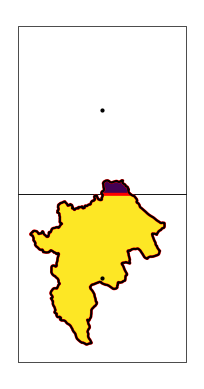

In [11]:
#plot results
basin_list = basin_shp.basin.unique()
basin_select = basin_list[0]
print(basin_select)
fig,ax = plt.subplots(1,1)
df_plot = fract_cells_grid_12km_basin[fract_cells_grid_12km_basin.basin==basin_select].copy()
df_plot.plot(ax=ax,column='fract_basin_area',edgecolor='r',zorder=2,lw=2)
basin_shp_proj[basin_shp_proj.basin==basin_select].boundary.plot(ax=ax,color='k')
xmin = df_plot.x.unique().min(); xmax = df_plot.x.unique().max();
ymin = df_plot.y.unique().min(); ymax = df_plot.y.unique().max();
grid_12km_cells[(grid_12km_cells.x>=xmin) & (grid_12km_cells.x<=xmax) & (grid_12km_cells.y>=ymin) & (grid_12km_cells.y<=ymax)].boundary.plot(ax=ax,color='k',lw=0.5,zorder=0)
grid_12km_sel_gdf[(grid_12km_sel_gdf.x>=xmin) & (grid_12km_sel_gdf.x<=xmax) & (grid_12km_sel_gdf.y>=ymin) & (grid_12km_sel_gdf.y<=ymax)].plot(ax=ax,color='k',markersize=4,zorder=2)
ax.set_axis_off()

# Save Output

In [13]:
len(fract_cells_grid_12km_basin.basin.unique())

1943

In [ ]:
#just basins that have full coverage
nfc = fract_cells_grid_12km_basin.groupby(['basin'])['fract_basin_area'].sum().reset_index()
nfc = nfc[nfc.fract_basin_area>0.99999999999].sort_values(by='fract_basin_area') #keep only basins with full coverage
fract_cells_grid_12km_basin = fract_cells_grid_12km_basin[fract_cells_grid_12km_basin.basin.isin(nfc.basin.unique())]
save_path = pwp+'abirn_vic/input_data/grid_cell_conversions/grid_12km_basin'
fract_cells_grid_12km_basin.drop(columns=['geometry','T2']).to_csv(save_path+'fract_cells_grid_12km_basin_'+reg_sel+'.csv',index=False)